# ¿Quién manda en el draft? Equilibrio y diversidad del meta profesional de Dota 2 (2025–2026)

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ) · 2026-2
**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque
**Entrega:** Proyecto Unidad 1 — EDA y calidad de datos
**Integrantes:** Apaza Mamani Ruben · Apaza Suca Elwin Junior · Mamani Quilca Richard · Quiza Apaza Kevin Manuel · Vilca Ochoa Nathaly Fiorella
**Arquitectura:** Kaggle + OpenDota → Bronze (originales) → Silver (tabla de draft validada) → Gold (indicadores por parche)

> **Cómo leer este notebook (también si nunca jugaste Dota 2).** La sección 1.2 explica el juego y todos los términos en 5 minutos.
> Cada tabla o gráfico va seguido de una interpretación en lenguaje simple.

| Parte | Secciones | Qué cubre |
|---|---|---|
| **A — Lo que pide la rúbrica** | 0–9 | Tema y pregunta · fuente y unidad de análisis · perfil y diccionario · calidad y diagnóstico |
| **B — Exploración de la pregunta** | 10–16 | Silver · diversidad · equilibrio · prioridad de draft · Gold · sesgos · conclusiones responsables |

> ✏️ = celda que completas tú · `# TODO` = código que debes terminar · Antes de entregar: **Kernel → Restart & Run All**.

---
# PARTE A — EDA y calidad de datos (rúbrica)

## 0. Preparación reproducible

### 0.1 Verificar entorno virtual activo
Buena práctica: confirmar que el kernel usa el entorno del proyecto (`Dota2env20262`) y no el Python del sistema.

In [10]:
import sys
import pandas as pd

print(sys.version)
print(sys.executable)

print(pd.__version__)
print("Entorno BigData listo")

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
d:\Cursos\BigData\EDA\Dota2env20262\Scripts\python.exe
3.0.6
Entorno BigData listo


### 0.2 Localizar la raíz del proyecto e importar módulos
Todas las rutas se construyen desde el archivo `proyecto.marker`. **No hay rutas absolutas**: el notebook funciona en cualquier computadora.

In [11]:
from pathlib import Path

_aqui = Path.cwd().resolve()
_raiz = next((p for p in [_aqui, *_aqui.parents] if (p / "proyecto.marker").is_file()), None)
if _raiz is None:
    raise FileNotFoundError("Abre este notebook desde dentro de la carpeta del proyecto.")
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import platform
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config, ingesta, metricas
from src.calidad import EvaluadorCalidad

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)

COLORES = {"navy": "#0D2137", "steel": "#2E86AB", "gold": "#F4B942", "coral": "#E55B4D",
           "green": "#27AE60", "teal": "#0E6B8B", "gray": "#64748B"}
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#F5F9FC",
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

print(f"Proyecto : {config.RAIZ}")
print(f"Python   : {platform.python_version()} ({platform.system()})")
print(f"Bronze   : {config.BRONZE.relative_to(config.RAIZ)}")
print(f"Silver   : {config.SILVER.relative_to(config.RAIZ)}")
print(f"Gold     : {config.GOLD.relative_to(config.RAIZ)}")

Proyecto : D:\Cursos\BigData\EDA\Proyecto_Dota2_Meta
Python   : 3.12.10 (Windows)
Bronze   : data\bronze
Silver   : data\silver
Gold     : data\gold


### 0.3 Verificar dependencias (sin modificar el entorno)

In [12]:
import importlib.util

REQUERIDAS = ["pandas", "numpy", "matplotlib", "seaborn", "pyarrow", "kaggle"]
faltan = [p for p in REQUERIDAS if importlib.util.find_spec(p) is None]
if faltan:
    raise ModuleNotFoundError("Faltan dependencias: " + ", ".join(faltan) +
                              ". Ejecuta desde la raíz: python -m pip install -r requirements.txt")
print("Dependencias verificadas:", ", ".join(REQUERIDAS))

Dependencias verificadas: pandas, numpy, matplotlib, seaborn, pyarrow, kaggle


---
## 1. Proyecto, tema e integrantes

### 1.1 Ficha del proyecto ✏️
- **Nombre del proyecto:** ¿Quién manda en el meta? Diversidad y equilibrio del Dota 2 profesional
- **Tema:** ✏️ (2–3 líneas: el draft profesional de Dota 2 como un problema de decisión con datos)
- **Integrantes:**
    - Apaza Mamani Ruben
    - Apaza Suca Elwin Junior
    - Mamani Quilca Richard
    - Quiza Apaza Kevin Manuel
    - Vilca Ochoa Nathaly Fiorella

### 1.2 Dota 2 en 5 minutos (para quien nunca jugó)

**Dota 2** es un videojuego de estrategia por equipos: **5 contra 5**. Un equipo juega del lado **Radiant** y el otro del lado **Dire**.
Gana el equipo que destruye la base principal del rival. Existe una escena profesional con ligas, torneos y premios millonarios.

Cada partida profesional tiene dos fases:

1. **Draft (antes de jugar).** Los capitanes de ambos equipos se turnan para **prohibir** (*ban*) y **elegir** (*pick*) personajes llamados **héroes**. Un héroe elegido por un equipo ya no lo puede usar el otro.
2. **Partida.** Los 10 héroes elegidos se enfrentan. El resultado se registra como victoria de Radiant o de Dire.

| Término | Qué significa | Si fuera fútbol... |
|---|---|---|
| **Héroe** | Personaje con habilidades propias. Hay más de 120 | Un jugador del plantel con un estilo propio |
| **Pick** | Elegir un héroe para tu equipo | Poner a un jugador en tu once titular |
| **Ban** | Prohibir un héroe para que nadie lo use | Vetar a la estrella rival antes del partido |
| **Draft** | La secuencia completa de bans y picks | La pizarra táctica antes del partido |
| **Captains Mode** | El formato de draft que se usa en torneos profesionales | El reglamento oficial del torneo |
| **Radiant / Dire** | Los dos lados del mapa | Local / visitante |
| **Parche** (7.40, 7.41…) | Actualización del juego que cambia el poder de los héroes | Un cambio de reglamento entre temporadas |
| **Meta** | Los héroes y estrategias que "están de moda" porque funcionan en el parche actual | El sistema táctico que todos copian esa temporada |
| **Pick rate / Ban rate** | % de partidas en que un héroe fue elegido / prohibido | % de partidos en que un jugador fue titular / vetado |
| **Contest rate** | Pick rate + ban rate: cuánto "importa" un héroe en el draft | Qué tan disputado es un jugador en el mercado |
| **Win rate** | % de veces que ganó el equipo que eligió ese héroe | % de victorias cuando ese jugador es titular |
| **Héroes efectivos** | "Es como si se usaran N héroes por igual" (medida de diversidad) | Cuántos jugadores rotan realmente en el equipo |

> **Por qué importa:** si en un parche se usan pocos héroes (meta concentrado), un analista puede preparar el draft enfocado en ellos.
> Si el meta es diverso, la preparación debe ser más amplia. Esa es la decisión que este proyecto quiere apoyar.

✏️ Revisa y adapta esta tabla con tus palabras. Es la base del glosario de la exposición (`docs/glosario_dota2.md`).

---
## 2. Pregunta motivadora y utilidad esperada

**Pregunta (aprobada por el docente):**
> **¿Qué tan equilibrado y diverso ha sido el meta competitivo de Dota 2 parche a parche, y cómo podría esa información ayudar a los analistas de equipos a priorizar su preparación de draft?**

**Tipo de pregunta:** Mejorar una decisión

**¿Quién la usaría y para qué?**
- Coachs de distintos equipos profesionales

**Sub-preguntas que guían el EDA** (todas descriptivas, sin afirmar causalidad):

| # | Sub-pregunta | Dimensión | Métrica | Sección |
|---|---|---|---|---|
| 1 | ¿Cuántos héroes distintos se eligen en cada parche y qué tan concentrado está su uso? | Diversidad | Héroes efectivos, cuota top-10, Gini | 11 |
| 2 | ¿Qué tan parejos son los win rates de los héroes en cada parche? | Equilibrio | Dispersión del win rate (con muestra mínima) | 12 |
| 3 | ¿Qué tan parejo es el resultado entre Radiant y Dire en cada parche? | Equilibrio | % de victorias de Radiant | 12 |
| 4 | ¿Qué héroes concentran la prioridad del draft en el parche más reciente? | Utilidad | Contest rate | 13 |

> ⚠️ La rúbrica de esta entrega termina en el diagnóstico de calidad (sección 9). La Parte B muestra **hacia dónde va** el análisis.

---
## 3. Fuente, período y condiciones de uso

### 3.1 Ficha de la fuente ✏️

| Campo | Valor |
|---|---|
| Dataset principal | Dota 2 Pro League Matches 2016–2026 (Kaggle) — `config.KAGGLE_URL` |
| Autor / mantenedor | BwandoWando |
| Origen de los datos | OpenDota API |
| Licencia / condiciones de uso | CC0: Public Domain |
| Frecuencia de actualización | Weekly (Updated a month ago) |
| Catálogos auxiliares | API pública de OpenDota: héroes (`/api/heroes`) y parches (`/api/constants/patch`) |
| Tamaño total del dataset | ~48.5 GB (2016–2026); aquí se usa solo una parte (ver 3.2) |
| Fecha de descarga | se registra en el manifiesto (3.5) |

### 3.2 Alcance: qué se descarga y por qué ✏️

- **Período:** 2025 completo + enero–septiembre 2026.
- **Por qué incluir 2025:** según el catálogo de parches, 2026 solo contiene **2 parches** (7.40 y 7.41). Para comparar "parche a parche" se necesitan más.
- **Tablas livianas** (`main_metadata`, `picks_bans`, `teams`) → todo el período.
- **`players`** (pesada) → solo 2026 y pocas columnas: se usa únicamente para reglas de consistencia.
- **Archivos excluidos** → tabla de abajo, con su justificación (gobierno de datos).

✏️ Explica con tus palabras por qué este recorte basta para tu pregunta.

In [13]:
print("Períodos            :", ", ".join(config.PERIODOS))
print("Tablas livianas     :", config.ARCHIVOS_LIVIANOS)
print("players.csv solo en :", config.PERIODOS_PLAYERS[0], "→", config.PERIODOS_PLAYERS[-1])
display(pd.DataFrame(config.ARCHIVOS_EXCLUIDOS.items(), columns=["archivo_excluido", "justificacion"]))

Períodos            : 2025, 202601, 202602, 202603, 202604, 202605, 202606, 202607, 202608, 202609
Tablas livianas     : ['main_metadata.csv', 'picks_bans.csv', 'teams.csv']
players.csv solo en : 202601 → 202609


,archivo_excluido,justificacion
0,chat.csv,Texto libre escrito por jugadores (privacidad)...
1,all_word_counts.csv,Derivado del chat; mismo motivo
2,cosmetics.csv,Objetos cosméticos; sin relación con la pregunta
3,teamfights.csv,Detalle de peleas; no se usa para medir el meta
4,objectives.csv,"Eventos del mapa (torres, Roshan); fuera del a..."
5,radiant_gold_adv.csv,Series de ventaja de oro; siguiente etapa
6,radiant_exp_adv.csv,Series de ventaja de experiencia; siguiente etapa


### 3.3 Catálogos de referencia (OpenDota)
Traducen códigos a nombres: `hero_id = 1` → *Anti-Mage*, `patch = 60` → *7.41*. Sin ellos, la audiencia vería solo números.

In [14]:
ingesta.descargar_catalogos()
heroes = ingesta.cargar_heroes()
parches = ingesta.cargar_parches()
print(f"Héroes en el catálogo: {len(heroes)}")

# Parches que caen dentro del período analizado (desde el vigente al iniciar 2025)
en_periodo = parches[parches["lanzamiento"] <= "2026-09-30"]
en_periodo = en_periodo[en_periodo["lanzamiento"] >= en_periodo.loc[en_periodo["lanzamiento"] <= "2025-01-01", "lanzamiento"].max()]
en_periodo

Catálogo heroes   OK  ->  data/bronze/catalogos/heroes.json
Catálogo parches  OK  ->  data/bronze/catalogos/parches.json
Héroes en el catálogo: 127


,patch,parche,lanzamiento
56,56,7.37,2024-08-01 07:30:27.355
57,57,7.38,2025-02-19 13:48:29.412
58,58,7.39,2025-05-22 23:36:01.602
59,59,7.40,2025-12-16 00:50:40.281
60,60,7.41,2026-03-24 00:50:59.580


### 3.4 Descarga reproducible desde Kaggle
Idempotente: si un archivo ya existe en `data/bronze/`, no se vuelve a descargar.

> 💡 Si es tu primera vez, prueba primero con un solo archivo: `ingesta.descargar_periodos(["202608"], ["picks_bans.csv"])`.

In [15]:
# Paso 1: tablas livianas para todo el período
ingesta.descargar_periodos(config.PERIODOS, config.ARCHIVOS_LIVIANOS)

[  1/30] 2025/main_metadata.csv ... OK (10.4 MB)
[  2/30] 2025/picks_bans.csv ... OK (20.9 MB)
[  3/30] 2025/teams.csv ... OK (7.5 MB)
[  4/30] 202601/main_metadata.csv ... OK (0.9 MB)
[  5/30] 202601/picks_bans.csv ... OK (1.8 MB)
[  6/30] 202601/teams.csv ... OK (0.6 MB)
[  7/30] 202602/main_metadata.csv ... OK (0.8 MB)
[  8/30] 202602/picks_bans.csv ... OK (1.5 MB)
[  9/30] 202602/teams.csv ... OK (0.6 MB)
[ 10/30] 202603/main_metadata.csv ... OK (0.8 MB)
[ 11/30] 202603/picks_bans.csv ... OK (1.7 MB)
[ 12/30] 202603/teams.csv ... OK (0.6 MB)
[ 13/30] 202604/main_metadata.csv ... OK (0.9 MB)
[ 14/30] 202604/picks_bans.csv ... OK (1.7 MB)
[ 15/30] 202604/teams.csv ... OK (0.6 MB)
[ 16/30] 202605/main_metadata.csv ... OK (0.8 MB)
[ 17/30] 202605/picks_bans.csv ... OK (1.6 MB)
[ 18/30] 202605/teams.csv ... OK (0.6 MB)
[ 19/30] 202606/main_metadata.csv ... OK (0.3 MB)
[ 20/30] 202606/picks_bans.csv ... OK (0.6 MB)
[ 21/30] 202606/teams.csv ... OK (0.2 MB)
[ 22/30] 202607/main_metadata.c

[WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/2025/main_metadata.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/2025/picks_bans.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/2025/teams.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202601/main_metadata.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202601/picks_bans.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202601/teams.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202602/main_metadata.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202602/picks_bans.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202602/teams.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202603/main_metadata.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202603/pick

In [16]:
# Paso 2: players.csv solo para 2026 (pesado: ~160 MB por mes, puede tardar)
ingesta.descargar_periodos(config.PERIODOS_PLAYERS, [config.ARCHIVO_PLAYERS])

[  1/9] 202601/players.csv ... OK (580.4 MB)
[  2/9] 202602/players.csv ... OK (423.7 MB)
[  3/9] 202603/players.csv ... OK (475.7 MB)
[  4/9] 202604/players.csv ... OK (501.7 MB)
[  5/9] 202605/players.csv ... OK (491.5 MB)
[  6/9] 202606/players.csv ... OK (190.5 MB)
[  7/9] 202607/players.csv ... OK (100.8 MB)
[  8/9] 202608/players.csv ... OK (153.9 MB)
[  9/9] 202609/players.csv ... OK (41.5 MB)


[WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202601/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202602/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202603/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202604/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202605/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202606/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202607/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202608/players.csv'),
 WindowsPath('D:/Cursos/BigData/EDA/Proyecto_Dota2_Meta/data/bronze/202609/players.csv')]

### 3.5 Manifiesto de trazabilidad (SHA-256)

In [17]:
manifiesto = ingesta.generar_manifiesto()
print(f"Archivos en Bronze: {len(manifiesto)} | Tamaño total: {manifiesto['tamano_mb'].sum():,.1f} MB")
display(manifiesto.groupby("archivo").agg(archivos=("periodo", "count"), mb=("tamano_mb", "sum")))
manifiesto.head()

Archivos en Bronze: 41 | Tamaño total: 3,016.9 MB


,archivos,mb
archivo,,
heroes.json,1,0.029
main_metadata.csv,10,15.354
parches.json,1,0.004
picks_bans.csv,10,30.764
players.csv,9,"2,959.686"
teams.csv,10,11.065


,periodo,archivo,ruta_relativa,tamano_mb,sha256,descargado_utc
0,2025,main_metadata.csv,data/bronze/2025/main_metadata.csv,10.415,5ca64888e7e291e87d0d6c0de6e5de689dd081acf29147...,2026-09-14 06:44
1,2025,picks_bans.csv,data/bronze/2025/picks_bans.csv,20.906,01edf5fe08cc0b323b4913989e9814eec3db0c12161fa8...,2026-09-14 06:44
2,2025,teams.csv,data/bronze/2025/teams.csv,7.547,74d868c734e4586f1c801256ffa01b3ea9475afd9d69d1...,2026-09-14 06:44
3,202601,main_metadata.csv,data/bronze/202601/main_metadata.csv,0.931,e9f712d6879436d07e16da254beb6217d483bdbbcfeeff...,2026-09-14 06:44
4,202601,picks_bans.csv,data/bronze/202601/picks_bans.csv,1.847,d341e3bae076eae62d7631eeddd8372219ab957b82c722...,2026-09-14 06:44


---
## 4. Unidad de análisis

### 4.1 Columnas reales de cada tabla
Se lee solo el encabezado (instantáneo). Se comparan con las columnas que el notebook espera.

In [18]:
periodo_muestra = config.PERIODOS[-1]
esperadas = {
    "main_metadata.csv": config.COLS_META_CLAVE,
    "picks_bans.csv": [config.PB_PARTIDA, config.PB_ES_PICK, config.PB_HEROE, config.PB_EQUIPO, config.PB_ORDEN],
    "teams.csv": [],
    "players.csv": config.COLS_PLAYERS,
}
for archivo, cols_esperadas in esperadas.items():
    periodo = config.PERIODOS_PLAYERS[-1] if archivo == "players.csv" else periodo_muestra
    try:
        cols = ingesta.columnas_de(archivo, periodo)
    except FileNotFoundError:
        print(f"\n{archivo}: no descargado"); continue
    faltan = [c for c in cols_esperadas if c not in cols]
    print(f"\n{archivo} ({len(cols)} columnas)")
    print("  ", ", ".join(cols[:45]), "..." if len(cols) > 45 else "")
    print("   ✅ contiene todas las columnas esperadas" if not faltan else f"   ⚠️ FALTAN: {faltan}  → ajusta src/config.py")


main_metadata.csv (39 columnas)
   version, match_id, leagueid, start_date_time, duration, series_id, series_type, cluster, replay_salt, radiant_win, pre_game_duration, match_seq_num, tower_status_radiant, tower_status_dire, barracks_status_radiant, barracks_status_dire, first_blood_time, lobby_type, human_players, game_mode, flags, engine, radiant_score, dire_score, radiant_team_id, radiant_logo, radiant_team_complete, dire_team_id, dire_logo, dire_team_complete, radiant_captain, dire_captain, patch, region, throw, loss, comeback, stomp, replay_url 
   ✅ contiene todas las columnas esperadas

picks_bans.csv (6 columnas)
   is_pick, hero_id, team, order, match_id, leagueid 
   ✅ contiene todas las columnas esperadas

teams.csv (10 columnas)
   match_id, leagueid, radiant.team_id, radiant.name, radiant.tag, radiant.logo_url, dire.team_id, dire.name, dire.tag, dire.logo_url 
   ✅ contiene todas las columnas esperadas

players.csv (156 columnas)
   player_slot, obs_placed, sen_placed, cr

### 4.2 ¿Qué representa una fila? ✏️

| Tabla | 1 fila representa... | Clave (única) | Se relaciona con |
|---|---|---|---|
| `main_metadata` | una partida profesional | `match_id` | — |
| `picks_bans` | una **acción del draft** (un pick o un ban) de un equipo en una partida | ✏️ (`match_id`, `order`)? | `main_metadata` por `match_id` |
| `teams` | ✏️ | ✏️ | ✏️ |
| `players` | el desempeño de un jugador en una partida | (`match_id`, `player_slot`) | `main_metadata` por `match_id` |
| catálogo `heroes` | un héroe del juego | `hero_id` | `picks_bans` por `hero_id` |
| catálogo `parches` | una versión del juego | `patch` | `main_metadata` por `patch` |

**Unidad de análisis principal:** la **acción de draft** (pick o ban), porque la pregunta trata sobre qué héroes eligen y prohíben los equipos.
La partida es la unidad secundaria (equilibrio Radiant/Dire y duración). ✏️ Explícalo con tus palabras.

```
 parches ──(patch)──► main_metadata ◄──(match_id)── picks_bans ──(hero_id)──► heroes
                           ▲
                           └────────(match_id)── players  (solo 2026, para consistencia)
```

---
## 5. Carga reproducible y evidencia básica

In [19]:
import time

t0 = time.perf_counter()
meta = ingesta.cargar_tabla("main_metadata.csv", config.PERIODOS)
pb = ingesta.cargar_tabla("picks_bans.csv", config.PERIODOS)
teams = ingesta.cargar_tabla("teams.csv", config.PERIODOS)
try:
    players = ingesta.cargar_tabla(config.ARCHIVO_PLAYERS, config.PERIODOS_PLAYERS, columnas=config.COLS_PLAYERS)
except FileNotFoundError:
    players = None
    print("players.csv no descargado: las reglas que lo usan se omitirán")
print(f"Carga completa en {time.perf_counter() - t0:,.1f} s")

def memoria_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

tablas = {"main_metadata": meta, "picks_bans": pb, "teams": teams, "players": players,
          "heroes (catálogo)": heroes, "parches (catálogo)": parches}
pd.DataFrame([{"tabla": n, "filas": len(d), "columnas": d.shape[1], "memoria_MB": memoria_mb(d)}
              for n, d in tablas.items() if d is not None])

Carga completa en 28.4 s


,tabla,filas,columnas,memoria_MB
0,main_metadata,44988,40,19.402
1,picks_bans,1062700,7,54.490
2,teams,44989,11,12.918
3,players,143670,10,10.841
4,heroes (catálogo),127,5,0.011
5,parches (catálogo),61,3,0.002


In [20]:
meta.head(3)

,version,match_id,leagueid,start_date_time,duration,series_id,series_type,cluster,replay_salt,radiant_win,pre_game_duration,match_seq_num,tower_status_radiant,tower_status_dire,barracks_status_radiant,barracks_status_dire,first_blood_time,lobby_type,human_players,game_mode,flags,engine,radiant_score,dire_score,radiant_team_id,radiant_logo,radiant_team_complete,dire_team_id,dire_logo,dire_team_complete,radiant_captain,dire_captain,patch,region,throw,loss,comeback,stomp,replay_url,periodo_origen
0,21.000,8107483721,17163,2025-01-01 00:09:05,2059,"938,494.000",1.000,274,"1,271,852,253.000",False,90,6817296376,'0000000100000110','0000011100100100','00110111','00111111',87,1,10,2,1,1,22,31,"9,025,669.000",NaN,1.000,"8,849,817.000",NaN,1.000,"315,850,275.000","188,408,746.000",56,3.000,NaN,NaN,52.000,"9,324.000",http://replay274.valve.net/570/8107483721_1271...,2025
1,21.000,8107511870,17163,2025-01-01 00:53:00,1856,"938,494.000",1.000,272,"1,100,232,577.000",False,90,6817319003,'0000000000100000','0000011111100100','00001100','00111111',164,1,10,2,5,1,16,45,"8,849,817.000",NaN,1.000,"9,025,669.000",NaN,1.000,"352,414,980.000","307,624,442.000",56,3.000,NaN,NaN,"6,220.000","15,460.000",http://replay272.valve.net/570/8107511870_1100...,2025
2,21.000,8107808159,17565,2025-01-01 08:01:42,2242,"938,509.000",1.000,145,"1,700,596,007.000",False,90,6817550308,'0000011110100110','0000011111110110','00111111','00111111',0,1,10,2,5,1,11,17,"9,645,837.000","7,416,500,508,731,896.000",1.000,"9,641,453.000","6,290,173,590,737,323.000",1.000,"400,042,066.000","402,486,366.000",56,19.000,NaN,NaN,-192.000,"8,961.000",http://replay145.valve.net/570/8107808159_1700...,2025


In [21]:
meta.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 44988 entries, 0 to 44987
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   version                  44988 non-null  float64
 1   match_id                 44988 non-null  int64  
 2   leagueid                 44988 non-null  int64  
 3   start_date_time          44988 non-null  str    
 4   duration                 44988 non-null  int64  
 5   series_id                37458 non-null  float64
 6   series_type              37458 non-null  float64
 7   cluster                  44988 non-null  int64  
 8   replay_salt              37458 non-null  float64
 9   radiant_win              44988 non-null  bool   
 10  pre_game_duration        44988 non-null  int64  
 11  match_seq_num            44988 non-null  int64  
 12  tower_status_radiant     44988 non-null  str    
 13  tower_status_dire        44988 non-null  str    
 14  barracks_status_radiant  44988 no

In [22]:
display(pb.head(12))
pb.info(memory_usage="deep")

,is_pick,hero_id,team,order,match_id,leagueid,periodo_origen
0,False,110,0,0,8107483721,17163,2025
1,False,41,1,1,8107483721,17163,2025
2,False,44,1,2,8107483721,17163,2025
3,False,70,0,3,8107483721,17163,2025
4,False,32,1,4,8107483721,17163,2025
5,False,67,1,5,8107483721,17163,2025
6,False,120,0,6,8107483721,17163,2025
7,True,2,0,7,8107483721,17163,2025
8,True,22,1,8,8107483721,17163,2025
9,False,97,0,9,8107483721,17163,2025


<class 'pandas.DataFrame'>
RangeIndex: 1062700 entries, 0 to 1062699
Data columns (total 7 columns):
 #   Column          Non-Null Count    Dtype
---  ------          --------------    -----
 0   is_pick         1062700 non-null  bool 
 1   hero_id         1062700 non-null  int64
 2   team            1062700 non-null  int64
 3   order           1062700 non-null  int64
 4   match_id        1062700 non-null  int64
 5   leagueid        1062700 non-null  int64
 6   periodo_origen  1062700 non-null  str  
dtypes: bool(1), int64(5), str(1)
memory usage: 54.5 MB


✏️ **Interpretación de la carga** (3–5 líneas):
- ¿Cuántas partidas y cuántas acciones de draft hay? ¿Cuántas acciones por partida en promedio?
- ¿Qué tipos de dato llegaron mal? (pista: `start_date_time` llega como texto; los ids de equipo como `float64` porque tienen nulos)
- ¿Hay columnas que no entenderías sin el diccionario? Anótalas: van a la sección 7.

---
## 6. Perfil descriptivo

### 6.1 Variables derivadas: de códigos a información legible

In [23]:
meta["fecha"] = pd.to_datetime(meta["start_date_time"], errors="coerce")
meta["mes"] = meta["fecha"].dt.to_period("M").astype("string")
meta["duracion_min"] = meta["duration"] / 60
meta["primera_sangre_min"] = meta["first_blood_time"] / 60
meta["ganador"] = meta["radiant_win"].map({True: "Radiant", False: "Dire"})
meta["modo_juego"] = meta["game_mode"].map(config.MODOS_JUEGO).fillna("Otro")
meta["tipo_lobby"] = meta["lobby_type"].map(config.TIPOS_LOBBY).fillna("Otro")

# Parche: número interno -> versión legible, ordenada cronológicamente
# Ojo: main_metadata YA tiene una columna "version" (versión del procesamiento de datos,
# p. ej. 22.0), que no es el parche. Por eso la columna legible se llama "parche".
orden_parches = parches.sort_values("patch")["parche"].tolist()
meta = meta.merge(parches[["patch", "parche"]], on="patch", how="left", validate="many_to_one")
meta["parche"] = pd.Categorical(meta["parche"], categories=orden_parches, ordered=True)

meta[["match_id", "fecha", "parche", "duracion_min", "ganador", "modo_juego", "tipo_lobby"]].head()

,match_id,fecha,parche,duracion_min,ganador,modo_juego,tipo_lobby
0,8107483721,2025-01-01 00:09:05,7.37,34.317,Dire,Captains Mode,Práctica (torneo privado)
1,8107511870,2025-01-01 00:53:00,7.37,30.933,Dire,Captains Mode,Práctica (torneo privado)
2,8107808159,2025-01-01 08:01:42,7.37,37.367,Dire,Captains Mode,Práctica (torneo privado)
3,8107860205,2025-01-01 08:54:22,7.37,26.800,Radiant,Captains Mode,Práctica (torneo privado)
4,8107907898,2025-01-01 09:41:43,7.37,42.417,Dire,Captains Mode,Práctica (torneo privado)


### 6.2 `describe()` explicado

| Estadístico | Qué responde |
|---|---|
| `count` | cuántos valores no nulos hay (compáralo con el total → incompletitud) |
| `mean` | promedio; sensible a valores extremos |
| `std` | dispersión alrededor del promedio |
| `min` / `max` | extremos; ayudan a detectar valores imposibles |
| `25%`, `50%`, `75%` | cuartiles; el 50 % es la **mediana**, robusta ante extremos |
| `skew` | asimetría: > 0.5 cola a la derecha; < −0.5 cola a la izquierda |

> No se interpretan promedios de `match_id`, `leagueid`, `patch` o `hero_id`: son **identificadores o códigos**, no cantidades.

In [24]:
cols_num = ["duracion_min", "primera_sangre_min", "radiant_score", "dire_score", "human_players"]
perfil = meta[cols_num].describe(percentiles=[.01, .25, .5, .75, .99]).T
perfil["nulos"] = meta[cols_num].isna().sum()
perfil["skew"] = meta[cols_num].skew()
display(perfil.round(2))

print("LECTURA GUIADA")
for col in cols_num:
    s = meta[col].dropna()
    rel = "mayor" if s.mean() > s.median() else "menor o igual"
    forma = "cola a la derecha" if s.skew() > 0.5 else "cola a la izquierda" if s.skew() < -0.5 else "aprox. simétrica"
    print(f"• {col}: N={len(s):,}; media={s.mean():.2f}; mediana={s.median():.2f}; "
          f"P1={s.quantile(.01):.2f}; P99={s.quantile(.99):.2f}. Media {rel} que mediana; {forma}.")

,count,mean,std,min,1%,25%,50%,75%,99%,max,nulos,skew
duracion_min,"44,988.000",33.910,10.110,6.070,15.650,27.170,31.850,39.120,66.030,119.130,0,1.180
primera_sangre_min,"44,988.000",2.160,1.980,0.000,0.000,0.450,1.830,3.180,8.670,18.000,0,1.250
radiant_score,"44,988.000",29.940,12.730,0.000,5.000,20.000,30.000,38.000,61.000,92.000,0,0.240
dire_score,"44,988.000",29.170,13.270,0.000,3.000,19.000,29.000,38.000,62.000,101.000,0,0.240
human_players,"44,988.000",10.000,0.000,10.000,10.000,10.000,10.000,10.000,10.000,10.000,0,0.000


LECTURA GUIADA
• duracion_min: N=44,988; media=33.91; mediana=31.85; P1=15.65; P99=66.03. Media mayor que mediana; cola a la derecha.
• primera_sangre_min: N=44,988; media=2.16; mediana=1.83; P1=0.00; P99=8.67. Media mayor que mediana; cola a la derecha.
• radiant_score: N=44,988; media=29.94; mediana=30.00; P1=5.00; P99=61.00. Media menor o igual que mediana; aprox. simétrica.
• dire_score: N=44,988; media=29.17; mediana=29.00; P1=3.00; P99=62.00. Media mayor que mediana; aprox. simétrica.
• human_players: N=44,988; media=10.00; mediana=10.00; P1=10.00; P99=10.00. Media menor o igual que mediana; aprox. simétrica.


In [25]:
# Variables categóricas: ¿cuántas categorías hay y cuál domina?
cols_cat = ["parche", "ganador", "modo_juego", "tipo_lobby", "leagueid", "region"]
display(meta[cols_cat].astype("string").describe().T)

for col in ["modo_juego", "tipo_lobby", "ganador"]:
    print(f"\n{col}:"); print(meta[col].value_counts(dropna=False).to_string())

,count,unique,top,freq
parche,44988,5,7.39,17737
ganador,44988,2,Radiant,23435
modo_juego,44988,3,Captains Mode,44117
tipo_lobby,44988,1,Práctica (torneo privado),44988
leagueid,44988,241,17233,6030
region,44146,16,3.0,23393



modo_juego:
modo_juego
Captains Mode      44117
All Pick             627
Ranked All Pick      244

tipo_lobby:
tipo_lobby
Práctica (torneo privado)    44988

ganador:
ganador
Radiant    23435
Dire       21553


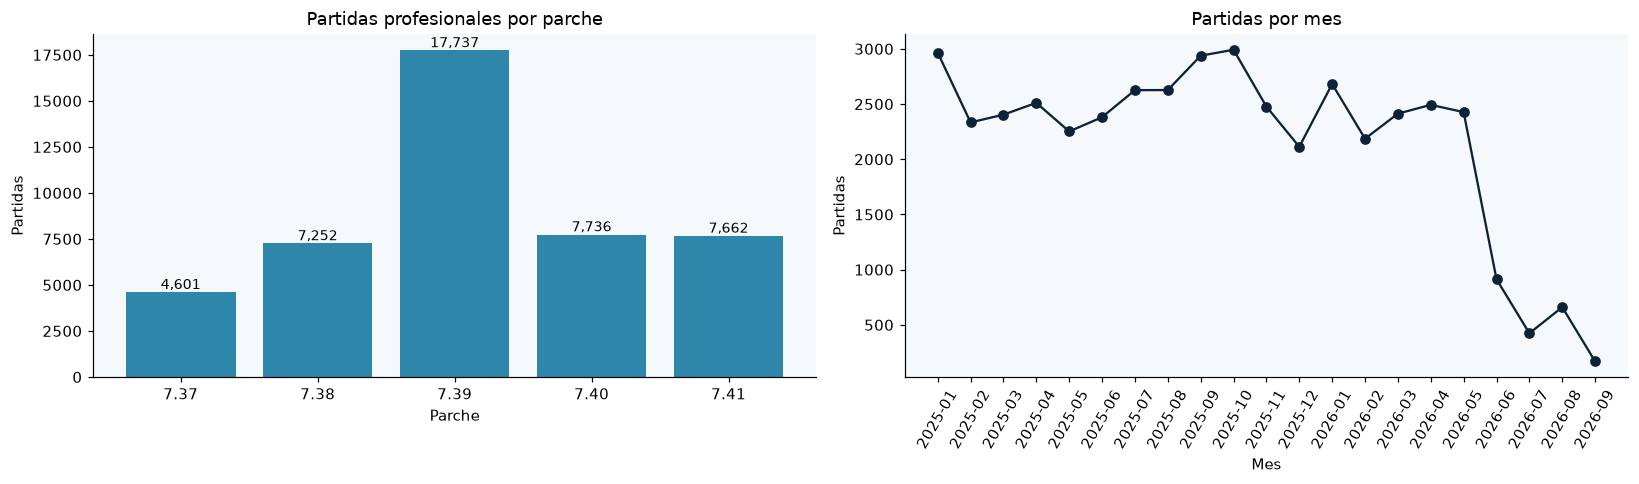

In [26]:
# ¿Cuántas partidas hay por parche y por mes? Un parche con pocas partidas pesa poco en las conclusiones.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

por_parche = meta["parche"].value_counts().sort_index()
por_parche = por_parche[por_parche > 0]
axes[0].bar(por_parche.index.astype(str), por_parche.values, color=COLORES["steel"])
axes[0].set(title="Partidas profesionales por parche", xlabel="Parche", ylabel="Partidas")
for i, v in enumerate(por_parche.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

por_mes = meta.groupby("mes").size()
axes[1].plot(por_mes.index, por_mes.values, marker="o", color=COLORES["navy"])
axes[1].set(title="Partidas por mes", xlabel="Mes", ylabel="Partidas")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.savefig(config.FIGURAS / "partidas_por_parche_y_mes.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# Perfil del draft: ¿cuántas acciones, picks y bans hay por partida?
acciones = pb.groupby(config.PB_PARTIDA).agg(acciones=(config.PB_ES_PICK, "size"),
                                              picks=(config.PB_ES_PICK, "sum"))
acciones["bans"] = acciones["acciones"] - acciones["picks"]
display(acciones.describe().T.round(2))
print("Combinaciones más frecuentes (acciones, picks, bans):")
print(acciones.value_counts().head(5).to_string())

,count,mean,std,min,25%,50%,75%,max
acciones,"44,359.000",23.960,0.530,11.000,24.000,24.000,24.000,24.000
picks,"44,359.000",10.000,0.070,9.000,10.000,10.000,10.000,13.000
bans,"44,359.000",13.950,0.560,1.000,14.000,14.000,14.000,14.000


Combinaciones más frecuentes (acciones, picks, bans):
acciones  picks  bans
24        10     14      43916
23        10     13        167
17        10     7          39
18        10     8          30
16        10     6          30


✏️ **Interpretación del perfil** (usa el molde *dato → significado → consecuencia*):
- Duración: ¿cuánto dura una partida típica? ¿Hay extremos sospechosos (P1 muy bajo, P99 muy alto)?
- ¿Todas las partidas son *Captains Mode*? ¿Qué implica para la comparación del draft?
- ¿Qué parche tiene menos partidas? ¿Qué tan confiables serán sus métricas?
- Draft: ¿la mayoría de partidas tiene 10 picks? ¿Cuántos bans? ¿Qué significan las combinaciones raras?

---
## 7. Diccionario de datos

### 7.1 Catálogo técnico (automático)

In [28]:
def catalogo_tecnico(df, tabla):
    return pd.DataFrame({
        "tabla": tabla, "columna": df.columns,
        "tipo_pandas": [str(t) for t in df.dtypes],
        "nulos_pct": (df.isna().mean() * 100).round(2).values,
        "unicos": [df[c].nunique(dropna=True) for c in df.columns],
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })

catalogo = pd.concat([catalogo_tecnico(meta, "main_metadata"), catalogo_tecnico(pb, "picks_bans")],
                     ignore_index=True)
catalogo.to_csv(config.OUTPUTS / "catalogo_tecnico.csv", index=False, encoding="utf-8-sig")
catalogo

,tabla,columna,tipo_pandas,nulos_pct,unicos,ejemplo
0,main_metadata,version,float64,0.000,2,21.000
1,main_metadata,match_id,int64,0.000,44988,8107483721
2,main_metadata,leagueid,int64,0.000,241,17163
3,main_metadata,start_date_time,str,0.000,44910,2025-01-01 00:09:05
4,main_metadata,duration,int64,0.000,3539,2059
5,main_metadata,series_id,float64,16.740,17821,"938,494.000"
6,main_metadata,series_type,float64,16.740,4,1.000
7,main_metadata,cluster,int64,0.000,40,274
8,main_metadata,replay_salt,float64,16.740,37458,"1,271,852,253.000"
9,main_metadata,radiant_win,bool,0.000,2,False


### 7.2 Diccionario para cualquier persona ✏️

El docente pidió que la exposición la entienda **alguien que no conoce Dota 2**. Por eso, además del formato de la rúbrica
(*columna, descripción, tipo, dominio, importancia*), cada columna lleva un **nombre simple** y un **ejemplo real**.

Las filas de `main_metadata` ya están completas con las columnas reales; completa y revisa las de `picks_bans` y las derivadas.

In [29]:
COLUMNAS_DICC = ["tabla", "columna", "nombre_simple", "que_significa", "ejemplo",
                 "tipo_escala", "unidad_dominio", "importancia"]
diccionario = pd.DataFrame([
    ("main_metadata", "match_id", "Código de partida", "Identificador único de cada partida", "8923283343",
     "Identificador", "Entero positivo, único", "Une todas las tablas"),
    ("main_metadata", "start_date_time", "Fecha y hora", "Momento en que empezó la partida", "2026-08-01 00:18:32",
     "Temporal", "Fecha válida dentro del período", "Asigna cada partida a un mes y a un parche"),
    ("main_metadata", "duration", "Duración", "Cuánto duró la partida", "2743 (≈ 46 min)",
     "Numérica continua", "Segundos, > 0", "Describe el ritmo del meta"),
    ("main_metadata", "radiant_win", "¿Ganó Radiant?", "True si ganó el lado Radiant; False si ganó Dire", "True",
     "Booleana", "True / False", "Resultado; base del win rate"),
    ("main_metadata", "patch", "Parche", "Versión del juego vigente (código interno)", "60 (= 7.41)",
     "Categórica ordinal", "Catálogo de parches de OpenDota", "Eje principal: 'parche a parche'"),
    ("main_metadata", "game_mode", "Modo de draft", "Formato de selección de héroes", "2 (= Captains Mode)",
     "Categórica codificada", "Constantes de OpenDota", "Solo Captains Mode es comparable"),
    ("main_metadata", "leagueid", "Liga / torneo", "Torneo al que pertenece la partida", "20030",
     "Identificador", "Entero positivo", "Permite ver qué ligas pesan más"),
    ("main_metadata", "human_players", "Jugadores humanos", "Cuántas personas jugaron", "10",
     "Numérica discreta", "Debe ser 10", "Detecta partidas incompletas"),
    ("main_metadata", "radiant_score / dire_score", "Eliminaciones", "Kills totales de cada lado", "37 / 30",
     "Numérica discreta", "≥ 0", "Consistencia con players"),
    ("picks_bans", config.PB_ES_PICK, "¿Elegido o prohibido?", "True = pick (elegido); False = ban (prohibido)", "✏️",
     "Booleana", "True / False", "Separa picks de bans"),
    ("picks_bans", config.PB_HEROE, "Héroe", "✏️", "✏️", "Categórica (código)", "Catálogo de héroes", "✏️"),
    ("picks_bans", config.PB_EQUIPO, "Lado", "✏️ (0 = Radiant, 1 = Dire: verifícalo)", "✏️", "✏️", "✏️", "✏️"),
    ("picks_bans", config.PB_ORDEN, "Turno del draft", "✏️", "✏️", "✏️", "✏️", "✏️"),
    ("derivada", "parche", "Parche legible", "Versión del juego, p. ej. 7.41", "7.41",
     "Categórica ordinal", "Catálogo de parches", "Etiqueta de todos los gráficos"),
    ("derivada", "duracion_min", "Duración (min)", "duration / 60", "45.7", "Numérica continua", "Minutos, > 0", "✏️"),
], columns=COLUMNAS_DICC)

diccionario.to_csv(config.OUTPUTS / "diccionario_datos.csv", index=False, encoding="utf-8-sig")
diccionario

,tabla,columna,nombre_simple,que_significa,ejemplo,tipo_escala,unidad_dominio,importancia
0,main_metadata,match_id,Código de partida,Identificador único de cada partida,8923283343,Identificador,"Entero positivo, único",Une todas las tablas
1,main_metadata,start_date_time,Fecha y hora,Momento en que empezó la partida,2026-08-01 00:18:32,Temporal,Fecha válida dentro del período,Asigna cada partida a un mes y a un parche
2,main_metadata,duration,Duración,Cuánto duró la partida,2743 (≈ 46 min),Numérica continua,"Segundos, > 0",Describe el ritmo del meta
3,main_metadata,radiant_win,¿Ganó Radiant?,True si ganó el lado Radiant; False si ganó Dire,True,Booleana,True / False,Resultado; base del win rate
4,main_metadata,patch,Parche,Versión del juego vigente (código interno),60 (= 7.41),Categórica ordinal,Catálogo de parches de OpenDota,Eje principal: 'parche a parche'
5,main_metadata,game_mode,Modo de draft,Formato de selección de héroes,2 (= Captains Mode),Categórica codificada,Constantes de OpenDota,Solo Captains Mode es comparable
6,main_metadata,leagueid,Liga / torneo,Torneo al que pertenece la partida,20030,Identificador,Entero positivo,Permite ver qué ligas pesan más
7,main_metadata,human_players,Jugadores humanos,Cuántas personas jugaron,10,Numérica discreta,Debe ser 10,Detecta partidas incompletas
8,main_metadata,radiant_score / dire_score,Eliminaciones,Kills totales de cada lado,37 / 30,Numérica discreta,≥ 0,Consistencia con players
9,picks_bans,is_pick,¿Elegido o prohibido?,True = pick (elegido); False = ban (prohibido),✏️,Booleana,True / False,Separa picks de bans


---
## 8. Evaluación de calidad (dimensiones DAMA-DMBOK)

| Dimensión | Pregunta | Ejemplo en este dataset |
|---|---|---|
| Completitud | ¿Están los datos que necesito? | `patch` no nulo |
| Unicidad | ¿Cuento dos veces lo mismo? | `match_id` único |
| Validez | ¿El valor pertenece al dominio permitido? | `hero_id` existe en el catálogo |
| Consistencia | ¿Los datos concuerdan entre columnas o tablas? | 10 picks por partida; marcador = suma de kills |
| Plausibilidad | ¿El valor es creíble? | duración entre X e Y minutos |
| Oportunidad | ¿Los datos cubren el período que la pregunta necesita? | cada parche con suficientes partidas |

> Meta: **al menos 2 reglas por dimensión** (las 4 primeras son obligatorias) y **al menos 2 que crucen tablas**.
> Para cada regla: justifica el umbral con conocimiento del juego y escribe el impacto **en términos de tu pregunta**.
> **No se borra nada aquí**: solo se mide. La exclusión, si corresponde, ocurre en Silver (sección 10) con justificación.

In [30]:
cal = EvaluadorCalidad()
heroes_validos = set(heroes["hero_id"])

### 8.1 Completitud

In [31]:
# EJEMPLO COMPLETO (modelo para las demás reglas)
cal.evaluar(
    regla="patch no nulo",
    dimension="Completitud",
    tabla="main_metadata",
    cumple=meta["patch"].notna(),
    impacto="Sin parche, la partida no puede asignarse a una versión: queda fuera de la comparación parche a parche",
    responsable="Mantenedor del dataset (o el equipo: imputar por fecha de lanzamiento)",
)

# TODO: equipos identificados (radiant_team_id y dire_team_id no nulos)
#       ¿Qué análisis se pierde si no se sabe qué equipo jugó?
# TODO: hero_id no nulo en picks_bans

{'regla': 'patch no nulo',
 'dimension': 'Completitud',
 'tabla': 'main_metadata',
 'cumple': 44988,
 'total': 44988,
 'incumplimientos': 0,
 'cumplimiento_pct': 100.0,
 'impacto': 'Sin parche, la partida no puede asignarse a una versión: queda fuera de la comparación parche a parche',
 'responsable': 'Mantenedor del dataset (o el equipo: imputar por fecha de lanzamiento)'}

### 8.2 Unicidad

In [32]:
cal.evaluar(
    regla="match_id único en main_metadata",
    dimension="Unicidad",
    tabla="main_metadata",
    cumple=~meta["match_id"].duplicated(keep=False),
    impacto="Una partida repetida cuenta doble en pick rate y win rate",
    responsable="Equipo de análisis (deduplicar en Silver)",
)

# TODO: (match_id, order) único en picks_bans
# Pista: ~pb.duplicated(subset=[config.PB_PARTIDA, config.PB_ORDEN], keep=False)

{'regla': 'match_id único en main_metadata',
 'dimension': 'Unicidad',
 'tabla': 'main_metadata',
 'cumple': 44988,
 'total': 44988,
 'incumplimientos': 0,
 'cumplimiento_pct': 100.0,
 'impacto': 'Una partida repetida cuenta doble en pick rate y win rate',
 'responsable': 'Equipo de análisis (deduplicar en Silver)'}

### 8.3 Validez

In [33]:
# TODO: hero_id de picks_bans existe en el catálogo de héroes
# Pista: pb[config.PB_HEROE].isin(heroes_validos)

# TODO: patch existe en el catálogo de parches  → meta["patch"].isin(parches["patch"])

# TODO: modo de juego = Captains Mode (game_mode == 2). ¿Es un error o una partida de otro formato?

# TODO: fecha convertible  → meta["fecha"].notna()

### 8.4 Consistencia (aquí está el valor diferencial)

In [34]:
# TODO 1 — Integridad referencial: todo match_id de picks_bans existe en main_metadata
# Pista: pb[config.PB_PARTIDA].isin(meta["match_id"])

# TODO 2 — 10 picks por partida (5 por lado)
# Pista: picks = pb[pb[config.PB_ES_PICK]].groupby(config.PB_PARTIDA).size()
#        cumple = meta["match_id"].map(picks).eq(10)

# TODO 3 — Coherencia temporal: el mes de la fecha coincide con la carpeta de origen
# Pista: para 2026, meta["fecha"].dt.strftime("%Y%m") == meta["periodo_origen"];
#        para "2025", basta comparar el año.

# TODO 4 — La partida ocurrió DESPUÉS del lanzamiento de su parche
# Pista: une meta con parches[["patch", "lanzamiento"]] y compara fecha >= lanzamiento

# TODO 5 (usa players, solo 2026) — marcador de Radiant = suma de kills de sus jugadores
# Pista: kills_rad = players[players["isRadiant"]].groupby("match_id")["kills"].sum()
#        m26 = meta[meta["match_id"].isin(players["match_id"])]
#        cumple = m26["radiant_score"].eq(m26["match_id"].map(kills_rad))

### 8.5 Plausibilidad

In [35]:
# TODO: duración plausible. ¿Qué umbral mínimo usarías? Investiga qué es un "remake" o un abandono.
# cal.evaluar("duración entre X y Y min", "Plausibilidad", "main_metadata",
#             cumple=meta["duracion_min"].between(X, Y), impacto="...", responsable="...")

# TODO: human_players == 10

# TODO: primera sangre (first_blood_time) >= 0 y menor que la duración

### 8.6 Oportunidad

In [36]:
print(f"Cobertura: {meta['fecha'].min():%Y-%m-%d} → {meta['fecha'].max():%Y-%m-%d}")
display(meta.groupby("parche", observed=True)
            .agg(partidas=("match_id", "nunique"), desde=("fecha", "min"), hasta=("fecha", "max")))

# TODO: regla de oportunidad. Ejemplo: "cada parche del período tiene al menos N partidas".
# Pista: evalúa sobre la tabla anterior (una fila por parche), no sobre meta.

Cobertura: 2025-01-01 → 2026-09-13


,partidas,desde,hasta
parche,,,
7.37,4601,2025-01-01 00:09:05,2025-02-19 13:38:04
7.38,7252,2025-02-19 13:59:43,2025-05-22 23:12:47
7.39,17737,2025-05-22 23:53:53,2025-12-16 00:27:47
7.40,7736,2025-12-16 01:08:13,2026-03-24 00:25:06
7.41,7662,2026-03-24 01:09:11,2026-09-13 18:27:46


### 8.7 Resultado consolidado

In [37]:
resultado = cal.resumen()
cal.guardar(config.OUTPUTS / "resultado_calidad.csv")
resultado

,regla,dimension,tabla,cumple,total,incumplimientos,cumplimiento_pct,impacto,responsable
0,patch no nulo,Completitud,main_metadata,44988,44988,0,100.000,"Sin parche, la partida no puede asignarse a un...",Mantenedor del dataset (o el equipo: imputar p...
1,match_id único en main_metadata,Unicidad,main_metadata,44988,44988,0,100.000,Una partida repetida cuenta doble en pick rate...,Equipo de análisis (deduplicar en Silver)


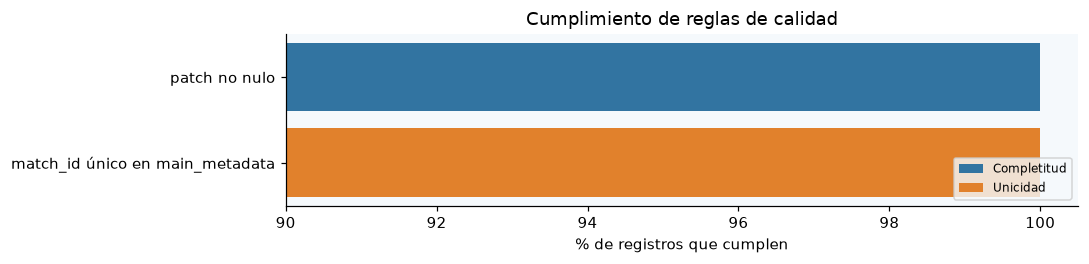

In [38]:
if not resultado.empty:
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(resultado) + 1.5))
    sns.barplot(data=resultado, y="regla", x="cumplimiento_pct", hue="dimension", dodge=False, ax=ax)
    ax.set(xlim=(min(90, resultado["cumplimiento_pct"].min() - 1), 100.5),
           xlabel="% de registros que cumplen", ylabel="", title="Cumplimiento de reglas de calidad")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(config.FIGURAS / "cumplimiento_calidad.png", dpi=150, bbox_inches="tight")
    plt.show()

In [39]:
# Inspecciona ejemplos reales de lo que falla (evidencia para el diagnóstico)
# TODO: cambia el nombre de la regla
meta.loc[cal.indices_que_fallan("patch no nulo")].head()

,version,match_id,leagueid,start_date_time,duration,series_id,series_type,cluster,replay_salt,radiant_win,pre_game_duration,match_seq_num,tower_status_radiant,tower_status_dire,barracks_status_radiant,barracks_status_dire,first_blood_time,lobby_type,human_players,game_mode,flags,engine,radiant_score,dire_score,radiant_team_id,radiant_logo,radiant_team_complete,dire_team_id,dire_logo,dire_team_complete,radiant_captain,dire_captain,patch,region,throw,loss,comeback,stomp,replay_url,periodo_origen,fecha,mes,duracion_min,primera_sangre_min,ganador,modo_juego,tipo_lobby,parche


---
## 9. Diagnóstico final ✏️

Elige los **2–3 problemas que más afectan a la pregunta** (no necesariamente los de menor %).

| # | Problema | Dimensión | Registros / % afectado | Cómo altera la descripción o la decisión del analista | Acción propuesta | Quién debe atenderla |
|---|---|---|---|---|---|---|
| 1 | ✏️ | ✏️ | ✏️ | ✏️ | ✏️ | ✏️ |
| 2 | ✏️ | ✏️ | ✏️ | ✏️ | ✏️ | ✏️ |
| 3 | ✏️ | ✏️ | ✏️ | ✏️ | ✏️ | ✏️ |

**Conclusión (3–5 líneas):** ✏️ ¿La calidad permite confiar en el análisis parche a parche? ¿Para qué sí, para qué no y con qué filtros?

> **Fin de la Parte A.** Esto es lo que evalúa la rúbrica de esta entrega.

---
# PARTE B — Exploración de la pregunta

> Todo lo que sigue es **descriptivo**: muestra *qué* pasó en cada parche, no *por qué*.

## 10. Capa Silver: tabla de draft validada

Una fila = una acción de draft, enriquecida con datos de la partida, el parche y el nombre del héroe.
Se excluyen **solo** los registros que incumplen reglas **críticas** explícitas; los rechazados se guardan para auditoría.

In [40]:
draft_stage = (
    pb.rename(columns={config.PB_PARTIDA: "match_id", config.PB_ES_PICK: "es_pick",
                       config.PB_HEROE: "hero_id", config.PB_EQUIPO: "equipo_cod", config.PB_ORDEN: "orden"})
      [["match_id", "es_pick", "hero_id", "equipo_cod", "orden"]]
      .merge(meta[["match_id", "fecha", "patch", "parche", "radiant_win", "duracion_min", "leagueid", "game_mode"]],
             on="match_id", how="left", validate="many_to_one")
      .merge(heroes[["hero_id", "heroe"]], on="hero_id", how="left", validate="many_to_one")
)
draft_stage["es_pick"] = draft_stage["es_pick"].astype(bool)
draft_stage["equipo"] = np.where(draft_stage["equipo_cod"] == 0, "Radiant", "Dire")
draft_stage["gano"] = ((draft_stage["equipo"] == "Radiant") & draft_stage["radiant_win"].eq(True)) | \
                      ((draft_stage["equipo"] == "Dire") & draft_stage["radiant_win"].eq(False))

# Reglas críticas (✏️ justifica cada una con un resultado de la sección 8)
criticas = (
    draft_stage["radiant_win"].notna()     # la partida existe en main_metadata
    & draft_stage["heroe"].notna()         # el héroe existe en el catálogo
    & draft_stage["parche"].notna()       # se conoce el parche
    & draft_stage["game_mode"].eq(2)       # solo Captains Mode es comparable
)
rechazados = draft_stage.loc[~criticas]
draft = draft_stage.loc[criticas].copy()

rechazados.to_csv(config.OUTPUTS / "silver_rechazados.csv", index=False, encoding="utf-8-sig")
try:
    draft.to_parquet(config.SILVER / "draft_silver.parquet", index=False)
    formato = "Parquet"
except Exception:
    draft.to_csv(config.SILVER / "draft_silver.csv", index=False, encoding="utf-8-sig")
    formato = "CSV"
print(f"Silver: {len(draft):,} acciones válidas | {len(rechazados):,} rechazadas "
      f"({100 * len(rechazados) / len(draft_stage):.2f} %) | formato: {formato}")
print(f"Partidas en Silver: {draft['match_id'].nunique():,} | Parches: {draft['parche'].nunique()}")

Silver: 1,058,501 acciones válidas | 4,199 rechazadas (0.40 %) | formato: Parquet
Partidas en Silver: 44,115 | Parches: 5


---
## 11. ¿Qué tan DIVERSO es el meta en cada parche? (sub-pregunta 1)

- **Héroes efectivos:** "es como si se jugaran N héroes por igual". Más alto = más diverso.
- **Cuota top-10:** qué % de todos los picks se llevan los 10 héroes más elegidos. Más alto = más concentrado.
- **Cobertura:** qué % de los héroes del juego se eligió al menos una vez.

,parche,partidas,picks,heroes_distintos,cobertura_pct,cuota_top10_pct,entropia_norm,heroes_efectivos,gini
0,7.37,4580,45800,125,98.430,22.440,0.940,92.820,0.440
1,7.38,6947,69470,125,98.430,20.850,0.940,96.130,0.410
2,7.39,17389,173890,126,99.210,18.720,0.950,101.880,0.370
3,7.40,7660,76600,127,100.000,21.000,0.950,98.880,0.390
4,7.41,7539,75390,127,100.000,21.540,0.950,100.200,0.380


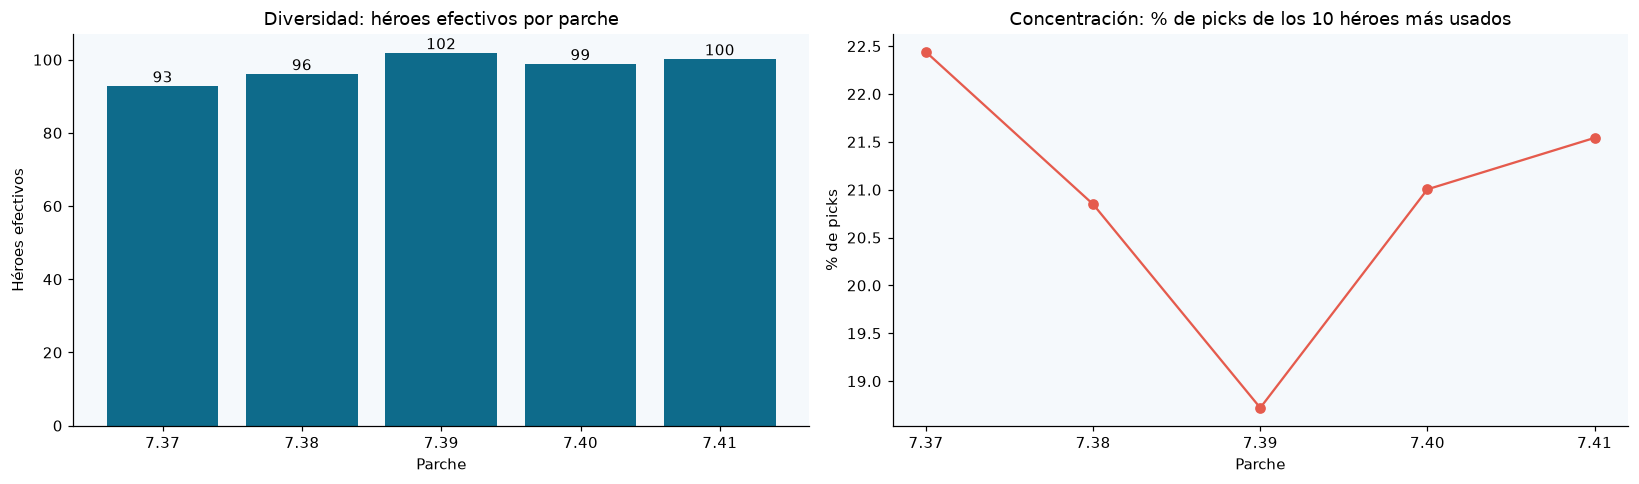

In [41]:
diversidad = metricas.diversidad_por_parche(draft, n_heroes_total=len(heroes))
display(diversidad.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = diversidad["parche"].astype(str)
axes[0].bar(x, diversidad["heroes_efectivos"], color=COLORES["teal"])
axes[0].set(title="Diversidad: héroes efectivos por parche", xlabel="Parche", ylabel="Héroes efectivos")
for i, v in enumerate(diversidad["heroes_efectivos"]):
    axes[0].text(i, v, f"{v:.0f}", ha="center", va="bottom")
axes[1].plot(x, diversidad["cuota_top10_pct"], marker="o", color=COLORES["coral"])
axes[1].set(title="Concentración: % de picks de los 10 héroes más usados", xlabel="Parche", ylabel="% de picks")
plt.tight_layout()
plt.savefig(config.FIGURAS / "diversidad_por_parche.png", dpi=150, bbox_inches="tight")
plt.show()

✏️ **Interpretación** (molde: hallazgo → evidencia → qué significa para el analista):
> *En el parche ___ el meta equivale a ___ héroes usados por igual, frente a ___ en el parche ___. Los 10 héroes más elegidos concentran el ___ % de los picks. Para un analista esto significa…*

---
## 12. ¿Qué tan EQUILIBRADO es el meta? (sub-preguntas 2 y 3)

### 12.1 Win rate por héroe: cuidado con la popularidad y las muestras pequeñas
Un héroe con 80 % de win rate en 5 partidas no es evidencia sólida. Solo se interpretan héroes con al menos
`config.MUESTRA_MINIMA` partidas (misma regla práctica del NoteBook07).

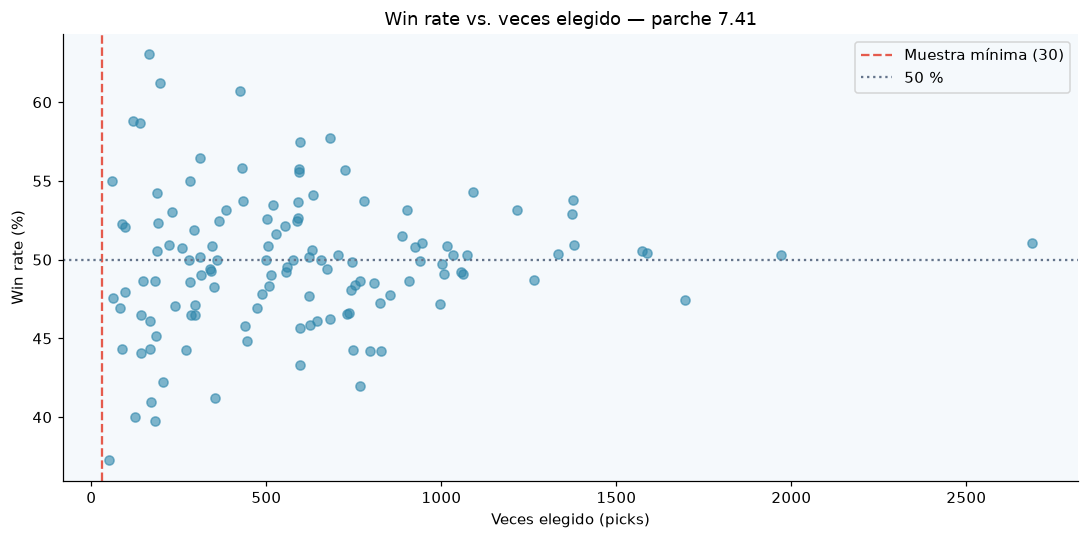

Héroes con muestra suficiente en 7.41: 127 de 127


In [42]:
tasas = metricas.tasas_por_heroe(draft).merge(heroes[["hero_id", "heroe"]], on="hero_id", how="left")
ultimo = diversidad["parche"].iloc[-1]
t_ult = tasas[tasas["parche"] == ultimo]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(t_ult["picks"], t_ult["win_rate_pct"], alpha=0.6, color=COLORES["steel"])
ax.axvline(config.MUESTRA_MINIMA, color=COLORES["coral"], ls="--", label=f"Muestra mínima ({config.MUESTRA_MINIMA})")
ax.axhline(50, color=COLORES["gray"], ls=":", label="50 %")
ax.set(title=f"Win rate vs. veces elegido — parche {ultimo}", xlabel="Veces elegido (picks)", ylabel="Win rate (%)")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURAS / "winrate_vs_picks_ultimo_parche.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Héroes con muestra suficiente en {ultimo}: "
      f"{(t_ult['picks'] >= config.MUESTRA_MINIMA).sum()} de {t_ult['hero_id'].nunique()}")

### 12.2 Dispersión de los win rates por parche
Si todos los héroes ganan cerca del 50 %, el parche está **equilibrado**. Si unos ganan mucho y otros poco, está **desbalanceado**.

,parche,heroes_con_muestra,desv_win_rate,win_rate_min,win_rate_max,pct_heroes_45_55
0,7.37,122,4.740,35.530,65.620,78.690
1,7.38,124,3.360,42.730,59.850,85.480
2,7.39,126,2.920,39.290,57.950,91.270
3,7.40,127,3.950,40.350,64.020,80.310
4,7.41,127,4.340,37.250,63.030,77.950


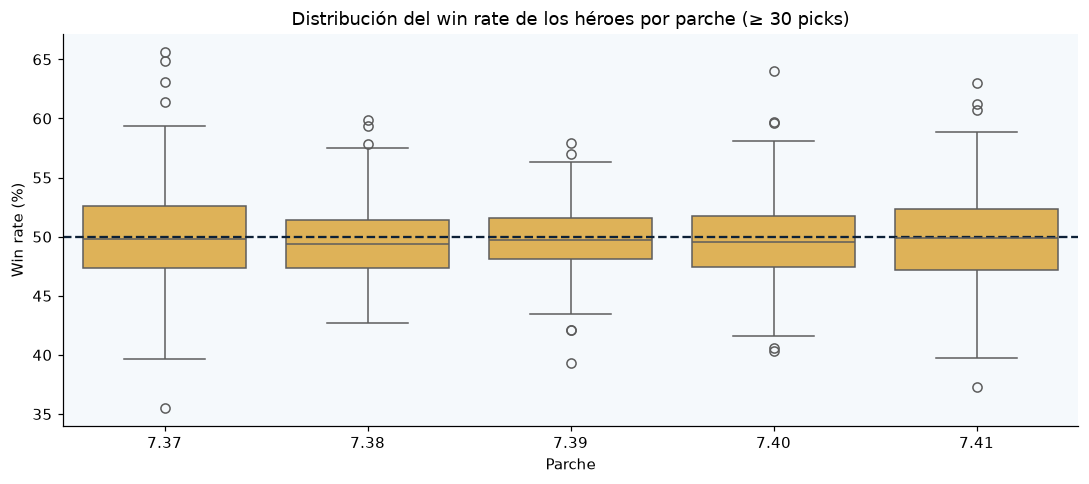

In [43]:
equilibrio = metricas.equilibrio_por_parche(tasas, config.MUESTRA_MINIMA)
display(equilibrio.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
datos = tasas[tasas["picks"] >= config.MUESTRA_MINIMA]
sns.boxplot(data=datos, x="parche", y="win_rate_pct", color=COLORES["gold"], ax=ax,
            order=[v for v in orden_parches if v in set(datos["parche"].astype(str))])
ax.axhline(50, color=COLORES["navy"], ls="--")
ax.set(title=f"Distribución del win rate de los héroes por parche (≥ {config.MUESTRA_MINIMA} picks)",
       xlabel="Parche", ylabel="Win rate (%)")
plt.tight_layout()
plt.savefig(config.FIGURAS / "equilibrio_winrate_por_parche.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.3 Equilibrio entre lados: Radiant vs. Dire

In [ ]:
# TODO: % de victorias de Radiant por parche, con el número de partidas
# Pista: meta.groupby("parche", observed=True)["radiant_win"].agg(["mean", "size"])
# Grafícalo con una línea de referencia en 50 %.

✏️ **Interpretación:** ¿qué parche fue más equilibrado entre héroes? ¿Y entre lados? ¿Hay alguna versión con un lado claramente favorecido?
Recuerda: describir no es explicar la causa.

---
## 13. ¿Qué priorizar en el draft? (sub-pregunta 4)

El **contest rate** (pick rate + ban rate) indica cuánto disputan los equipos a un héroe.
Es la señal más directa de qué debe preparar un analista para el parche vigente.

,heroe,picks,bans,pick_rate_pct,ban_rate_pct,contest_rate_pct,win_rate_pct
617,Pangolier,1587,2708,21.100,35.900,57.000,50.400
587,Rubick,2687,1566,35.600,20.800,56.400,51.100
539,Beastmaster,946,2642,12.500,35.000,47.600,51.100
515,Puck,887,2559,11.800,33.900,45.700,51.500
513,Shadow Fiend,1696,1657,22.500,22.000,44.500,47.500
570,Doom,1090,2257,14.500,29.900,44.400,54.300
619,Hoodwink,1970,1259,26.100,16.700,42.800,50.300
621,Snapfire,1216,2001,16.100,26.500,42.700,53.100
607,Ember Spirit,1374,1803,18.200,23.900,42.100,52.900
566,Batrider,592,2567,7.900,34.000,41.900,55.700


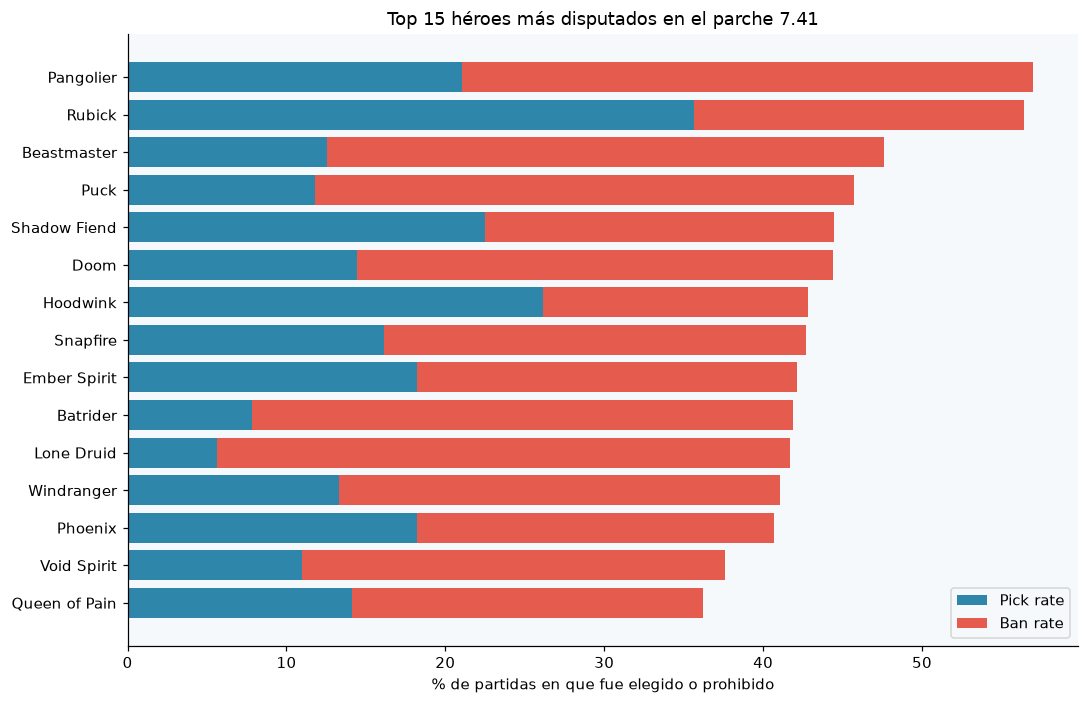

In [44]:
TOP_N = 15
prioridad = (t_ult.sort_values("contest_rate_pct", ascending=False).head(TOP_N)
                  [["heroe", "picks", "bans", "pick_rate_pct", "ban_rate_pct", "contest_rate_pct", "win_rate_pct"]])
display(prioridad.round(1))

fig, ax = plt.subplots(figsize=(10, 6.5))
p = prioridad.iloc[::-1]
ax.barh(p["heroe"], p["pick_rate_pct"], color=COLORES["steel"], label="Pick rate")
ax.barh(p["heroe"], p["ban_rate_pct"], left=p["pick_rate_pct"], color=COLORES["coral"], label="Ban rate")
ax.set(title=f"Top {TOP_N} héroes más disputados en el parche {ultimo}",
       xlabel="% de partidas en que fue elegido o prohibido")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(config.FIGURAS / "prioridad_draft_ultimo_parche.png", dpi=150, bbox_inches="tight")
plt.show()

✏️ **Interpretación para el analista:** ¿qué héroes debería dominar (o saber neutralizar) un equipo en el parche más reciente?
¿Hay héroes más prohibidos que elegidos? ¿Qué te dice eso?

---
## 14. Capa Gold: indicadores listos para presentar

In [45]:
gold = {
    "diversidad_por_parche.csv": diversidad,
    "equilibrio_por_parche.csv": equilibrio,
    "tasas_heroe_parche.csv": tasas,
    f"prioridad_draft_{ultimo}.csv": prioridad,
}
for nombre, tabla in gold.items():
    tabla.to_csv(config.GOLD / nombre, index=False, encoding="utf-8-sig")
    print(f"Gold → {(config.GOLD / nombre).relative_to(config.RAIZ).as_posix()}  ({len(tabla):,} filas)")

Gold → data/gold/diversidad_por_parche.csv  (5 filas)
Gold → data/gold/equilibrio_por_parche.csv  (5 filas)
Gold → data/gold/tasas_heroe_parche.csv  (630 filas)
Gold → data/gold/prioridad_draft_7.41.csv  (15 filas)


---
## 15. Sesgos y limitaciones ✏️

Completa la columna **¿Presente?** (Sí / Posible / No) y explica con evidencia del notebook.

| Sesgo | Cómo aparece aquí | ¿Presente? | Evidencia / efecto |
|---|---|---|---|
| **Selección** | Solo partidas de las ligas que registra el dataset; no todo el Dota profesional | ✏️ | ✏️ |
| **Muestra pequeña** | Héroes poco elegidos tienen win rates extremos | ✏️ | ✏️ (sección 12.1) |
| **Popularidad** | Un héroe muy elegido acumula victorias por volumen, no por eficacia | ✏️ | ✏️ |
| **Temporal (parche)** | Las subversiones (7.41a, 7.41b…) quedan agrupadas en un solo parche | ✏️ | ✏️ |
| **Confusión** | El win rate de un héroe depende también de qué equipo lo elige (los equipos fuertes eligen ciertos héroes) | ✏️ | ✏️ |
| **Dependencia** | Los 10 picks de una partida no son independientes entre sí | ✏️ | ✏️ |

---
## 16. Conclusiones responsables ✏️

Cada conclusión sigue la plantilla del curso: **Hallazgo → Evidencia → Interpretación → Limitación**.

| # | Hallazgo | Evidencia (número o gráfico) | Interpretación (sin causalidad) | Limitación |
|---|---|---|---|---|
| 1 | ✏️ Diversidad | ✏️ | ✏️ | ✏️ |
| 2 | ✏️ Equilibrio | ✏️ | ✏️ | ✏️ |
| 3 | ✏️ Prioridad de draft | ✏️ | ✏️ | ✏️ |

**Respuesta a la pregunta motivadora (4–6 líneas):** ✏️

---
### ✅ Checklist antes de entregar
- [ ] Kernel → Restart & Run All termina sin errores
- [ ] Ninguna ruta absoluta (`D:\...`, `C:\...`)
- [ ] Ninguna celda ✏️ conserva el texto guía
- [ ] Cada tabla o gráfico va seguido de su interpretación en lenguaje simple
- [ ] Al menos 2 reglas por dimensión (4 obligatorias) y 2 entre tablas
- [ ] `outputs/`: manifiesto, catálogo técnico, diccionario y resultado de calidad generados